# 08 — Does the premise survive uniform circuit noise?

## Premise

The paper's model (SM A) has two knobs per round: a data flip `p_data = p_stab ⊕ p_idle(Δt)` and
a syndrome-record flip `p_read = b_read·p`, with `b_read` **assumed**. 07 and 07b kept a trace of
that: idle noise hit the data only, once per interval, and the ancillas never dephased.

Here two constraints are relaxed:
1. **Ancillas get no special treatment.** Every qubit, ancilla or data, has the same noise model:
   the same gate noise and the same dephasing, applied in every layer of every round
   (7 layers of `t_R/7`), and over the wait between rounds. No `b_read` is put in anywhere.
   Whatever readout error the circuit has is *measured* from its detection events.
2. **Two-qubit errors on the full circuit**: `DEPOLARIZE2(p_2q)` after every CX, data–ancilla
   included, so ancilla faults spread onto the data (as in 07 and 07b).

**The premise under test** has three parts:
- **(P1)** there is still an interior optimal interval Δt\*;
- **(P2)** the circuit still *looks* phenomenological: its readout error does not depend on Δt,
  and its data error is a fixed per-round part plus the idle error of the wait;
- **(P3)** the paper's model, fed parameters **measured** from the circuit at one interval, predicts
  Δt\*.

Idle noise is 07's (Z only, linear `γ` and quadratic `c`), gate noise 07's (H2-1E ratios ×4.76),
textbook Stim gates (07b: the native decomposition moves Δt\* by under 8%).

**Result.** The premise survives. With uniform noise on every qubit and nothing assumed about
readout:

| | result | § |
| --- | --- | --- |
| **(P1)** interior optimum | yes, all 9 curves (d = 3, 5, 7 × linear, quadratic, mixed) | 3 |
| **(P2)** readout independent of Δt | `p_read(Δt) / p_read(1)` = 0.996–1.010, Δt = 1 to 16 | 2 |
| **(P2)** data error = per-round part + wait | measured / predicted = 0.996–1.004 | 2 |
| **measured `b_read`** | 0.98–1.02 from the gates alone; 1.08–1.15 with linear dephasing (ancillas dephase too) | 2 |
| **(P3)** Δt\* predicted from one calibration at Δt = 1 | d = 3: +16–18%; d = 5: +3–6%; d = 7: −5% to −2% | 4 |
| `p_L` at the optimum, prediction / circuit | 0.95–1.11 (d = 3), 0.74 (d = 5), 0.51 (d = 7) | 4 |
| treating ancillas like the data, against exempting them | Δt\* moves −1.3% to +4.9% | 5 |

## 0. Setup

In [1]:
import sys, pathlib, time
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['mathtext.fontset'] = 'cm'

sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
from qec_timing.circuit_level import runcache
from qec_timing.circuit_level.stim_memory import idle_channel
from qec_timing.circuit_level.timed_memory import (TimedMemory, phenomenological_circuit,
                                                   phenomenological_error, edge_probabilities,
                                                   xor, LAYERS)

pd.set_option('display.width', 200)
FIGDIR = pathlib.Path('figures')
BLUE, ORANGE, AQUA, GRAY, RED = '#1f5aa6', '#d9822b', '#2a9d8f', '#888888', '#c0392b'

H2 = dict(p1=1.89e-5, p2=1.05e-3, p_meas0=6e-4, p_meas1=1.39e-3, p_init=4e-5)
P2 = 5e-3
SCALE = P2 / H2['p2']
GATES = dict(p1=H2['p1'] * SCALE, p2=P2,
             p_meas=0.5 * (H2['p_meas0'] + H2['p_meas1']) * SCALE,
             p_init=H2['p_init'] * SCALE)
T = 192
DISTANCES = (3, 5, 7)
SHOTS, SEEDS = 100_000, (1, 2)
KEYS = (('lin', 0.3), ('quad', 0.01), ('mixed', (0.3, 0.01)))
R_CAL, SHOTS_CAL = 20, 400_000          # edge measurement: rounds, shots
EXP = '08_uniform_noise_premise'
N_WORKERS = min(16, mp.cpu_count())
print({k: f'{v:.3g}' for k, v in GATES.items()}, f'{N_WORKERS} workers')

{'p1': '9e-05', 'p2': '0.005', 'p_meas': '0.00474', 'p_init': '0.00019'} 16 workers


In [2]:
# ---- 07's helpers, copied verbatim (dt_grid, rate, optimum, idle_of) ----
def dt_grid(d, n=16):
    Rs = sorted({int(round(T / x)) for x in np.geomspace(1.0, T / d, n)
                 if round(T / x) >= d}, reverse=True)
    return [(T / R, R) for R in Rs]


def rate(F, N):
    p = F / N
    s = np.sqrt(max(p * (1 - p), 1e-12) / N)
    if p >= 0.5:
        return np.nan, np.nan
    return -np.log(1 - 2 * p) / (2 * T), s / ((1 - 2 * p) * T)


def optimum(df, rel=1.3, n_boot=2000, seed=0):
    df = df[(df.pL < 0.45) & np.isfinite(df.r)].reset_index(drop=True)
    x, y, s = np.log(df.dt.values), df.r.values, df.sr.values
    i = int(np.argmin(y))
    w = np.where(y <= rel * y[i])[0]
    lo, hi = w.min(), w.max()
    while hi - lo + 1 < 5 and (lo > 0 or hi < len(y) - 1):
        lo, hi = max(lo - 1, 0), min(hi + 1, len(y) - 1)
    sl = slice(lo, hi + 1)

    def vertex(yy):
        a, b, _ = np.polyfit(x[sl], np.log(yy[sl]), 2, w=yy[sl] / s[sl])
        if a <= 0:
            return x[sl][np.argmin(yy[sl])]
        return float(np.clip(-b / (2 * a), x[sl][0], x[sl][-1]))

    rng = np.random.default_rng(seed)
    boots = [vertex(np.maximum(y + rng.normal(0, s), 1e-12)) for _ in range(n_boot)]
    q16, q84 = np.exp(np.percentile(boots, [16, 84]))
    band = df.dt.values[(y - y[i]) <= np.sqrt(s ** 2 + s[i] ** 2)]
    return dict(dt_star=float(np.exp(vertex(y))), lo=float(q16), hi=float(q84),
                lowest=float(df.dt.values[i]), band=(round(band.min(), 2), round(band.max(), 2)),
                interior=bool(0 < i < len(y) - 1))


def idle_of(key):
    fam, val = key[0], key[1]
    if fam == 'lin':
        return val * P2, 0.0
    if fam == 'quad':
        return 0.0, val * P2
    return val[0] * P2, val[1] * P2


def label(key):
    return f'{key[0]} {key[1]}'

In [3]:
# ---- jobs: (kind, sorted params), cached in runcache, run in parallel ----
def _memory(p):
    gamma, c = p['gamma'], p['c']
    # stim_memory's quadratic term is sin^2(kappa*t/2); kappa = 2 sqrt(c)  (07)
    return TimedMemory('rotated', p['d'], p1=p['p1'], p2=p['p2'], p_meas=p['p_meas'],
                       p_init=p['p_init'], dephase_linear=gamma, dephase_quad=2 * np.sqrt(c),
                       ancilla_idle=p['ancilla_idle'])


def compute(kind, p):
    if kind == 'full':
        _, _, f = _memory(p).logical_error(p['dt'], p['R'], p['shots'], p['seed'])
        return dict(fails=f, shots=p['shots'])
    if kind == 'edges':
        return edge_probabilities(_memory(p).circuit(p['dt'], p['R']), p['shots'], p['seed'])
    if kind == 'pheno':
        _, _, f = phenomenological_error('rotated', p['d'], p['R'], p['p_data'], p['p_read'],
                                         p['shots'], p['seed'])
        return dict(fails=f, shots=p['shots'])
    raise ValueError(kind)


def job(kind, **p):
    p = {k: (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in p.items()}
    return (kind, tuple(sorted(p.items())))


def get(j):
    kind, items = j
    p = dict(items)
    hit = runcache.load(EXP, {'kind': kind, **p})
    if hit is None:
        hit = compute(kind, p)
        runcache.save(EXP, {'kind': kind, **p}, hit)
    return hit


def run_all(jobs):
    jobs = list(dict.fromkeys(jobs))
    todo = [j for j in jobs if runcache.load(EXP, {'kind': j[0], **dict(j[1])}) is None]
    cost = lambda j: dict(j[1])['d'] ** 2 * dict(j[1])['R'] * dict(j[1])['shots']
    todo.sort(key=lambda j: -cost(j))
    t0 = time.time()
    if todo:
        with mp.get_context('fork').Pool(N_WORKERS) as pool:
            list(pool.imap_unordered(get, todo, chunksize=1))
    print(f'{len(jobs)} jobs, {len(todo)} computed [{time.time() - t0:.0f}s]')


def mem_params(d, key, dt, R, ancilla_idle=True, gates=GATES):
    g, c = idle_of(key)
    return dict(d=d, dt=dt, R=R, gamma=g, c=c, ancilla_idle=ancilla_idle, **gates)


def full_jobs(d, key, ancilla_idle=True, gates=GATES):
    return [job('full', **mem_params(d, key, dt, R, ancilla_idle, gates), shots=SHOTS, seed=sd)
            for dt, R in dt_grid(d) for sd in SEEDS]


def edge_job(d, key, dt, ancilla_idle=True, gates=GATES):
    return job('edges', **mem_params(d, key, dt, R_CAL, ancilla_idle, gates),
               shots=SHOTS_CAL, seed=1)


def pheno_jobs(d, pdata_of_dt, p_read):
    return [job('pheno', d=d, R=R, p_data=float(pdata_of_dt(dt)), p_read=float(p_read),
                shots=SHOTS, seed=sd) for dt, R in dt_grid(d) for sd in SEEDS]


def curve(jobs_list):
    # jobs_list from *_jobs: consecutive seeds per dt, in dt_grid order
    rows = []
    by_dt = {}
    for j in jobs_list:
        p = dict(j[1])
        dt = p.get('dt')
        key = (dt if dt is not None else T / p['R'], p['R'])
        h = get(j)
        F, N = by_dt.get(key, (0, 0))
        by_dt[key] = (F + h['fails'], N + h['shots'])
    for (dt, R), (F, N) in sorted(by_dt.items()):
        r, sr = rate(F, N)
        rows.append(dict(dt=dt, R=R, pL=F / N, r=r, sr=sr))
    return pd.DataFrame(rows)


def q_wait(key, dt):
    # Z probability of the idle channel over the wait between rounds: what an idle benchmark measures
    g, c = idle_of(key)
    return idle_channel(dt - 1.0, 0.0, g, 2 * np.sqrt(c))[2]

## 1. Checks

**(a) The model.** Noiseless: zero detection events. Structure: one idle channel after each of the
7 `TICK`s of a round and one for the wait, each on **all** qubits, data and ancilla alike.

**(b) The measurement.** The edge estimator `p_ij` (Google 2021) applied to the paper's model with
known `p_data` and `p_read` must return them.

In [4]:
d = 3
g, c = idle_of(('mixed', (0.3, 0.01)))
M = TimedMemory('rotated', d, **GATES, dephase_linear=g, dephase_quad=2 * np.sqrt(c))
circ = M.circuit(4.0, 5)
noiseless = TimedMemory('rotated', d).circuit(4.0, 5)
det, obs = noiseless.compile_detector_sampler(seed=1).sample(2000, separate_observables=True)
flat = list(circ.flattened())
chans = [i for i in flat if i.name == 'PAULI_CHANNEL_1']
n_q = len({t.value for i in flat for t in i.targets_copy() if t.is_qubit_target})
print(f'noiseless: {det.sum()} detection events, {obs.sum()} logical flips')
print(f'idle channels: {len(chans)} for 5 rounds (expected {5 * (LAYERS + 1)}); '
      f'targets per channel: {sorted({len(i.targets_copy()) for i in chans})}, qubits in circuit: {n_q}')
lay, wt = idle_channel(1 / LAYERS, 0, g, 2 * np.sqrt(c)), idle_channel(3.0, 0, g, 2 * np.sqrt(c))
print(f'per layer pZ = {lay[2]:.3e}, wait (dt - 1 = 3) pZ = {wt[2]:.3e}; pX = pY = 0: {lay[0] == lay[1] == wt[0] == wt[1] == 0}')
assert det.sum() == 0 and obs.sum() == 0 and len(chans) == 5 * (LAYERS + 1)
assert all(len(i.targets_copy()) == n_q for i in chans)

rows = []
for pd_in, pr_in in ((0.005, 0.005), (0.01, 0.02), (0.03, 0.005)):
    e = edge_probabilities(phenomenological_circuit('rotated', 5, R_CAL, pd_in, pr_in), SHOTS_CAL)
    rows.append({'p_data in': pd_in, 'p_data measured': round(e['p_data'], 5), '+/-': round(e['p_data_se'], 5),
                 'p_read in': pr_in, 'p_read measured': round(e['p_read'], 5), '+/- ': round(e['p_read_se'], 5),
                 'diagonal': round(e['p_diag'], 5)})
print('\n', pd.DataFrame(rows).to_string(index=False))

noiseless: 0 detection events, 0 logical flips
idle channels: 40 for 5 rounds (expected 40); targets per channel: [17], qubits in circuit: 17
per layer pZ = 2.153e-04, wait (dt - 1 = 3) pZ = 4.946e-03; pX = pY = 0: True



  p_data in  p_data measured     +/-  p_read in  p_read measured    +/-   diagonal
     0.005          0.00499 0.00001      0.005          0.00500 0.00001   0.00000
     0.010          0.01000 0.00002      0.020          0.02001 0.00002   0.00000
     0.030          0.03008 0.00003      0.005          0.00502 0.00002   0.00004


## 2. The circuit, read as a phenomenological model

For each distance and idle setting, the edge probabilities at Δt = 1, 2, 4, 8, 16 (20 rounds,
400,000 shots each): `p_read` (time-like edges) and `p_data` (space-like ⊕ diagonal edges: a
flip of the shared data qubit at any time in the round). Plus the same circuit with **no idle
noise**, which gives the gate-only data error per round, `p_stab`.

**The measured readout multiplier** is `b_read = p_read / p_stab`: the paper's definition, with
both sides measured.

Each number is a mean over the bulk edges of one run (216–1,824 edges). Statistical errors are
below 1% of the value at 400,000 shots (§1b recovers known values to 0.1%); the edges themselves
differ systematically (bulk against near-boundary), so the comparisons below are ratios of means
over the *same* edges.

In [5]:
DTS_CAL = (1.0, 2.0, 4.0, 8.0, 16.0)
NOIDLE = ('lin', 0.0)
jobs = [edge_job(d, k, dt) for d in DISTANCES for k in KEYS for dt in DTS_CAL]
jobs += [edge_job(d, NOIDLE, 1.0) for d in DISTANCES]
jobs += [edge_job(d, k, 1.0, ancilla_idle=False) for d in DISTANCES for k in KEYS]
run_all(jobs)

rows = []
for d in DISTANCES:
    gate = get(edge_job(d, NOIDLE, 1.0))
    for k in KEYS:
        e1 = get(edge_job(d, k, 1.0))
        for dt in DTS_CAL:
            e = get(edge_job(d, k, dt))
            pred = xor(e1['p_data'], q_wait(k, dt))
            rows.append({'d': d, 'idle': label(k), 'dt': dt,
                         'p_read': e['p_read'], 'p_read / p_read(1)': e['p_read'] / e1['p_read'],
                         'p_data': e['p_data'], 'p_data(1) + wait': pred,
                         'p_data / (p_data(1) + wait)': e['p_data'] / pred,
                         'diag share': e['p_diag'] / e['p_data']})
EDGES = pd.DataFrame(rows)
fmt = {'p_read': '{:.5f}', 'p_data': '{:.5f}', 'p_data(1) + wait': '{:.5f}',
       'p_read / p_read(1)': '{:.3f}', 'p_data / (p_data(1) + wait)': '{:.3f}', 'diag share': '{:.2f}'}
print(EDGES.to_string(index=False, formatters={k: v.format for k, v in fmt.items()}))

57 jobs, 0 computed [0s]
 d              idle   dt  p_read p_read / p_read(1)  p_data p_data(1) + wait p_data / (p_data(1) + wait) diag share
 3           lin 0.3  1.0 0.01005              1.000 0.01042          0.01042                       1.000       0.39
 3           lin 0.3  2.0 0.01006              1.001 0.01186          0.01188                       0.998       0.34
 3           lin 0.3  4.0 0.01003              0.998 0.01476          0.01482                       0.996       0.27
 3           lin 0.3  8.0 0.01008              1.002 0.02072          0.02070                       1.001       0.20
 3           lin 0.3 16.0 0.01006              1.001 0.03255          0.03245                       1.003       0.13
 3         quad 0.01  1.0 0.00902              1.000 0.00881          0.00881                       1.000       0.40
 3         quad 0.01  2.0 0.00898              0.996 0.00887          0.00886                       1.001       0.40
 3         quad 0.01  4.0 0.00900      

In [6]:
rows = []
for d in DISTANCES:
    gate = get(edge_job(d, NOIDLE, 1.0))
    rows.append({'d': d, 'idle': 'none (gates only)', 'p_stab': gate['p_data'], 'p_read': gate['p_read'],
                 'b_read = p_read / p_stab': gate['p_read'] / gate['p_data'], 'p_read, ancillas exempt': np.nan})
    for k in KEYS:
        e1, ex = get(edge_job(d, k, 1.0)), get(edge_job(d, k, 1.0, ancilla_idle=False))
        rows.append({'d': d, 'idle': label(k), 'p_stab': gate['p_data'], 'p_read': e1['p_read'],
                     'b_read = p_read / p_stab': e1['p_read'] / gate['p_data'],
                     'p_read, ancillas exempt': ex['p_read']})
BREAD = pd.DataFrame(rows)
print(BREAD.to_string(index=False, float_format=lambda v: f'{v:.4g}'))
print(f"\n(for reference: p_meas = {GATES['p_meas']:.4g}, so b_read would be "
      f"{GATES['p_meas'] / BREAD['p_stab'].iloc[0]:.2f}-{GATES['p_meas'] / BREAD['p_stab'].iloc[-1]:.2f} "
      f"if the record flip were the only readout error)")

 d              idle   p_stab   p_read  b_read = p_read / p_stab  p_read, ancillas exempt
 3 none (gates only)  0.00878 0.008994                     1.024                      NaN
 3           lin 0.3  0.00878  0.01005                     1.145                 0.009051
 3         quad 0.01  0.00878 0.009017                     1.027                 0.008977
 3 mixed (0.3, 0.01)  0.00878  0.01003                     1.142                  0.00901
 5 none (gates only)  0.00954 0.009449                    0.9905                      NaN
 5           lin 0.3  0.00954  0.01048                     1.098                 0.009432
 5         quad 0.01  0.00954 0.009452                    0.9908                 0.009432
 5 mixed (0.3, 0.01)  0.00954   0.0105                       1.1                 0.009423
 7 none (gates only) 0.009854 0.009652                    0.9795                      NaN
 7           lin 0.3 0.009854  0.01069                     1.084                 0.009646
 7        

## 3. (P1) The sweeps: is there still an interior optimum?

The full circuit, uniform noise, 07's Δt grid at `T = 192`, 2 × 100,000 shots per point.

In [7]:
run_all([j for d in DISTANCES for k in KEYS for j in full_jobs(d, k)])
FULL = {(d, k): curve(full_jobs(d, k)) for d in DISTANCES for k in KEYS}
OPT = {key: optimum(df) for key, df in FULL.items()}
print(pd.DataFrame([{'d': d, 'idle': label(k), 'dt* (fit)': round(o['dt_star'], 2),
                     '16-84%': f"{o['lo']:.2f}-{o['hi']:.2f}", 'lowest dt': round(o['lowest'], 2),
                     'interior': o['interior'], 'pL at min': round(FULL[(d, k)].pL.min(), 4)}
                    for (d, k), o in OPT.items()]).to_string(index=False))

288 jobs, 0 computed [0s]


 d              idle  dt* (fit)      16-84%  lowest dt  interior  pL at min
 3           lin 0.3      10.12 10.03-10.20       9.14      True     0.2282
 3         quad 0.01       8.25   8.21-8.28       9.14      True     0.0912
 3 mixed (0.3, 0.01)       5.50   5.47-5.54       5.33      True     0.2542
 5           lin 0.3       5.35   5.31-5.39       5.49      True     0.1726
 5         quad 0.01       7.19   7.13-7.24       7.11      True     0.0501
 5 mixed (0.3, 0.01)       3.80   3.78-3.82       4.27      True     0.1831
 7           lin 0.3       3.48   3.44-3.51       3.76      True     0.1091
 7         quad 0.01       6.59   6.48-6.71       7.38      True     0.0238
 7 mixed (0.3, 0.01)       2.82   2.80-2.84       3.00      True     0.1162


## 4. (P3) Predicting Δt\* from measured parameters

The paper's model (ideal gates, one data flip per round, one record flip per syndrome and final
readout bit), swept on the same grid, with its two parameters taken three ways:

| arm | `p_data(Δt)` | `p_read` | what it tests |
| --- | --- | --- | --- |
| **measured once** | `p_data(1) ⊕ q_wait(Δt−1)` | `p_read(1)` | the realistic protocol: one calibration run at Δt = 1, plus an idle benchmark |
| **measured at each Δt** | `p_data(Δt)` from §2's estimator at that Δt | `p_read(Δt)` | whether the phenomenological *structure* suffices, with no extrapolation |
| **assumed `b_read` = 1** | as *measured once* | `p_stab` (gate-only) | what assuming the paper's `b_read` costs |

`q_wait` is the idle channel's own Z probability: what a perfect single-qubit idle benchmark returns.

The `p_ij` estimator assumes errors are rare and graph-like. At the longest intervals, where the
data error per round reaches ~0.2, it breaks down and returns negative edges. Such intervals are
dropped from the *measured at each Δt* arm and listed below the table. They lie far beyond Δt\*,
where `p_L` is near ½ and the fit excludes them anyway. The *measured once* arm only uses Δt = 1.

In [8]:
def arms(d, k):
    e1 = get(edge_job(d, k, 1.0))
    gate = get(edge_job(d, NOIDLE, 1.0))
    once = lambda dt: xor(e1['p_data'], q_wait(k, dt))
    out = {'measured once': pheno_jobs(d, once, e1['p_read']),
           'assumed b_read = 1': pheno_jobs(d, once, gate['p_data'])}
    each = []
    for dt, R in dt_grid(d):
        e = get(edge_job(d, k, dt))
        if min(e['p_read'], e['p_diag'], e['p_space']) < 0:
            DROPPED.append((d, label(k), dt, round(e['p_data'], 3)))
            continue                     # the estimator has broken down (see the note above)
        each += [job('pheno', d=d, R=R, p_data=float(e['p_data']), p_read=float(e['p_read']),
                     shots=SHOTS, seed=sd) for sd in SEEDS]
    out['measured at each dt'] = each
    return out


run_all([edge_job(d, k, dt) for d in DISTANCES for k in KEYS for dt, _ in dt_grid(d)])
DROPPED = []
ARMS = {}
for d in DISTANCES:
    for k in KEYS:
        for name, js in arms(d, k).items():
            ARMS[(d, k, name)] = js
run_all([j for js in ARMS.values() for j in js])
PH = {key: curve(js) for key, js in ARMS.items()}
PHOPT = {key: optimum(df) for key, df in PH.items()}

rows = []
for d in DISTANCES:
    for k in KEYS:
        o = OPT[(d, k)]
        so = (o['hi'] - o['lo']) / 2
        row = {'d': d, 'idle': label(k), 'full circuit': round(o['dt_star'], 2)}
        for name in ('measured once', 'measured at each dt', 'assumed b_read = 1'):
            p = PHOPT[(d, k, name)]
            row[name] = f"{p['dt_star']:.2f} ({p['dt_star'] / o['dt_star'] - 1:+.0%})"
        row['pL at min: once / full'] = round(PH[(d, k, 'measured once')].pL.min() / FULL[(d, k)].pL.min(), 2)
        rows.append(row)
PRED = pd.DataFrame(rows)
print(PRED.to_string(index=False))
print('\nintervals dropped from "measured at each dt" (estimator broke down: a negative edge):',
      sorted(set(DROPPED)))

144 jobs, 0 computed [0s]
862 jobs, 0 computed [0s]


 d              idle  full circuit measured once measured at each dt assumed b_read = 1  pL at min: once / full
 3           lin 0.3         10.12  11.80 (+17%)        11.61 (+15%)       11.41 (+13%)                    0.95
 3         quad 0.01          8.25   9.59 (+16%)         9.57 (+16%)        9.44 (+14%)                    1.11
 3 mixed (0.3, 0.01)          5.50   6.51 (+18%)         6.59 (+20%)        6.48 (+18%)                    0.98
 5           lin 0.3          5.35    5.49 (+3%)          5.49 (+3%)         5.36 (+0%)                    0.74
 5         quad 0.01          7.19    7.59 (+6%)         7.92 (+10%)         7.59 (+6%)                    0.74
 5 mixed (0.3, 0.01)          3.80    4.03 (+6%)          4.04 (+6%)         3.91 (+3%)                    0.75
 7           lin 0.3          3.48    3.31 (-5%)          3.29 (-5%)         3.28 (-6%)                    0.52
 7         quad 0.01          6.59    6.48 (-2%)          6.59 (+0%)         6.53 (-1%)                 

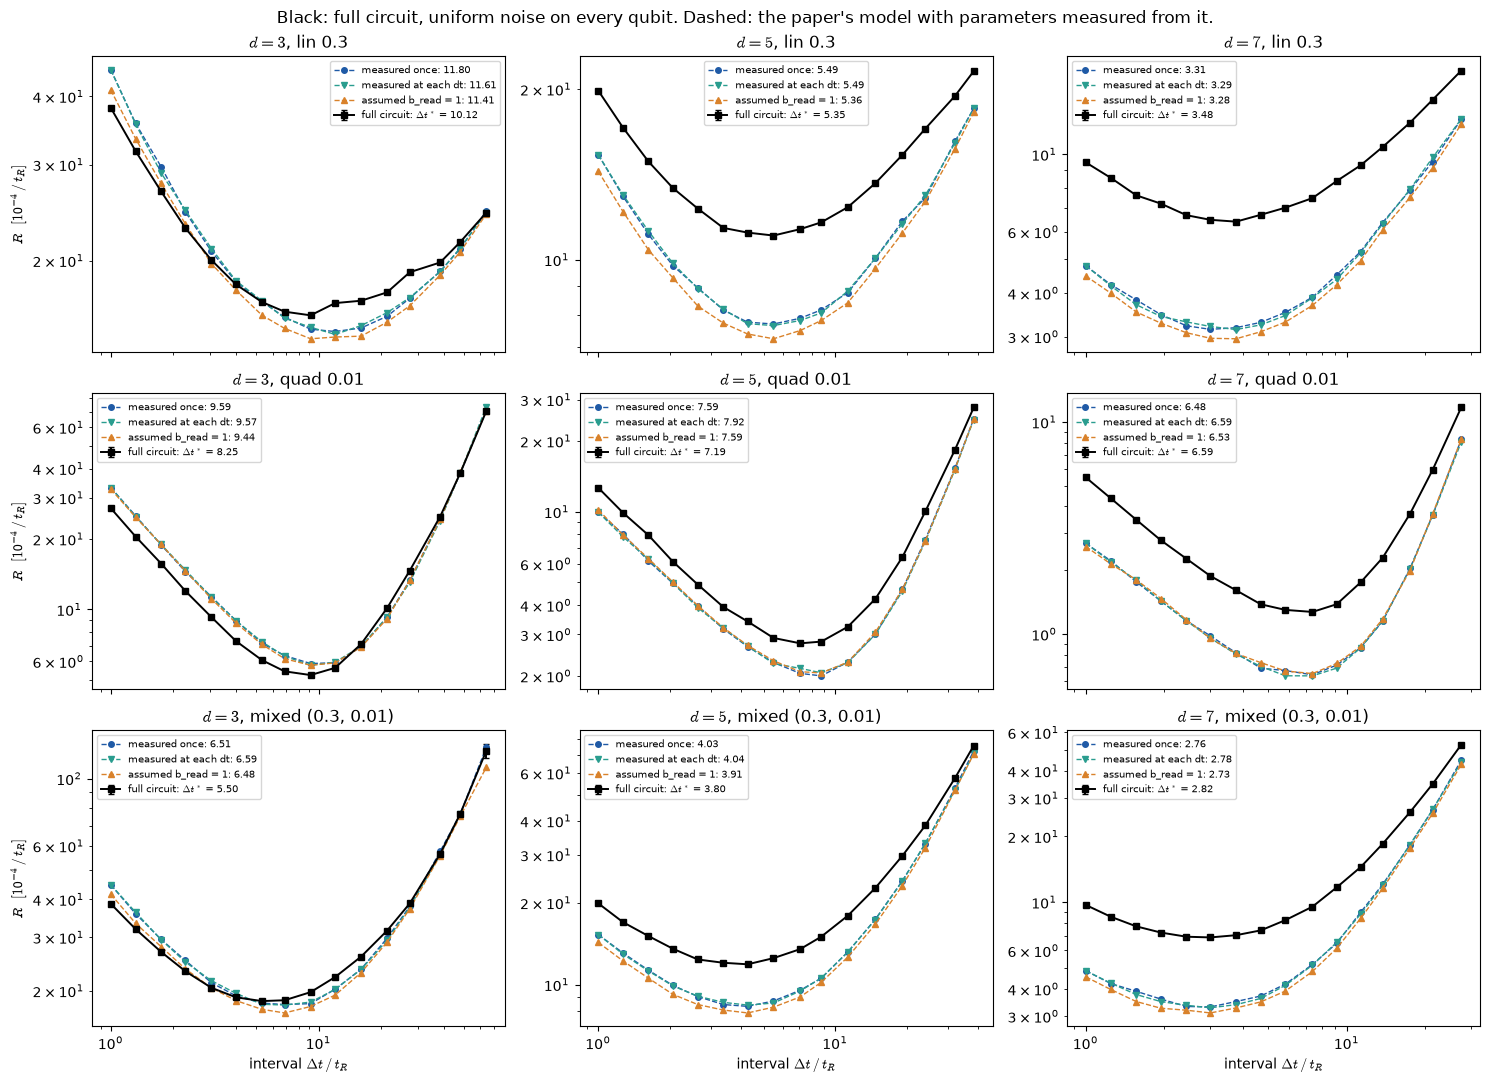

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex='col')
STY = {'measured once': (BLUE, 'o'), 'measured at each dt': (AQUA, 'v'), 'assumed b_read = 1': (ORANGE, '^')}
for j, d in enumerate(DISTANCES):
    for i, k in enumerate(KEYS):
        ax = axes[i, j]
        df = FULL[(d, k)]
        ax.errorbar(df.dt, df.r * 1e4, yerr=df.sr * 1e4, fmt='s-', ms=4, lw=1.4, color='k', capsize=2,
                    label=f"full circuit: $\\Delta t^*$ = {OPT[(d, k)]['dt_star']:.2f}")
        for name, (col, mk) in STY.items():
            p = PH[(d, k, name)]
            ax.plot(p.dt, p.r * 1e4, mk + '--', ms=4, lw=1, color=col,
                    label=f"{name}: {PHOPT[(d, k, name)]['dt_star']:.2f}")
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_title(f'$d = {d}$, {label(k)}')
        if j == 0:
            ax.set_ylabel(r'$R$  $[10^{-4}\,/\,t_R]$')
        if i == 2:
            ax.set_xlabel(r'interval $\Delta t\,/\,t_R$')
        ax.legend(fontsize=7)
fig.suptitle('Black: full circuit, uniform noise on every qubit. Dashed: the paper\'s model with parameters measured from it.')
fig.tight_layout()
fig.savefig(FIGDIR / '08_premise_uniform_noise.png', dpi=130, bbox_inches='tight', facecolor='white')

## 5. Diagnostic: what ancilla dephasing does

Not a model choice. The same full sweep with the ancillas exempt from idle noise, to show what
treating them like the data contributes.

In [10]:
run_all([j for d in DISTANCES for k in KEYS for j in full_jobs(d, k, ancilla_idle=False)])
rows = []
for d in DISTANCES:
    for k in KEYS:
        ex = optimum(curve(full_jobs(d, k, ancilla_idle=False)))
        o = OPT[(d, k)]
        rows.append({'d': d, 'idle': label(k), 'dt* uniform': round(o['dt_star'], 2),
                     'dt* ancillas exempt': round(ex['dt_star'], 2),
                     'uniform / exempt': round(o['dt_star'] / ex['dt_star'], 3)})
ANC = pd.DataFrame(rows)
print(ANC.to_string(index=False))

288 jobs, 0 computed [0s]


 d              idle  dt* uniform  dt* ancillas exempt  uniform / exempt
 3           lin 0.3        10.12                 9.65             1.049
 3         quad 0.01         8.25                 8.35             0.988
 3 mixed (0.3, 0.01)         5.50                 5.32             1.035
 5           lin 0.3         5.35                 5.11             1.047
 5         quad 0.01         7.19                 7.29             0.987
 5 mixed (0.3, 0.01)         3.80                 3.70             1.026
 7           lin 0.3         3.48                 3.35             1.036
 7         quad 0.01         6.59                 6.37             1.034
 7 mixed (0.3, 0.01)         2.82                 2.70             1.044


## 6. Findings

Each finding says where it comes from: **measured here**, **repo** (a choice made in this repo's
code) or **interpretation** (my reading, not tested).

**1. (P1) The trade-off survives.** (Measured here, §3.) Every curve has an interior optimum: Δt\*
= 10.1, 8.3, 5.5 (d = 3), 5.4, 7.2, 3.8 (d = 5), 3.5, 6.6, 2.8 (d = 7) for linear, quadratic and
mixed idle noise. All are 2–10% longer than 07's values for the same settings (07: data-only
idle noise). Ancilla dephasing explains at most 5% of that (finding 6). *Interpretation, untested:*
the rest comes from spreading the data's dephasing through the round's layers instead of
applying it once at the round's start. Uniform noise moves the numbers a little and leaves the
picture unchanged.

**2. (P2) Seen through its detection events, the full circuit IS the paper's model.** (Measured
here, §2.) Over Δt = 1 to 16, the measured readout error stays within ±1% of its Δt = 1 value at
every distance and idle setting: it does not depend on the interval, as the paper assumes. The
measured data error equals the Δt = 1 value composed with the idle error of the wait to within
±0.4%. The paper's decomposition `p_data = p_stab ⊕ p_idle(Δt)` with a constant `p_read` holds,
even though 37–40% of the per-round data error comes from faults *inside* the round (diagonal
edges). Those faults are still graph-like, and they fold into the per-round term.

**3. `b_read` measured: about 1 from the gates, more with ancilla dephasing.** (Measured here, §2.)
- From gate noise alone, `b_read` = 1.02, 0.99, 0.98 at d = 3, 5, 7. The record flip `p_meas`
  supplies only about half of `p_read`; the ancilla's own gate faults (four CNOTs, `H`, reset)
  supply the rest.
- At H2's ratios that lands close to the paper's `b_read = 1` (interpretation: coincidental, set
  by H2's `p_meas/p_2q`; not a property of the code).
- Ancilla dephasing raises it to 1.08–1.15 under linear idle noise. The rise vanishes when the
  ancillas are exempt (§2, last column), so it is entirely ancilla dephasing.
- Quadratic idle noise adds nothing to readout: over one layer (`t_R/7`) it is second-order small.
- Because measured `b_read` ≈ 1, the *assumed b_read = 1* arm predicts almost the same as the
  measured one (§4).

**4. (P3) Predicting Δt\* from one calibration works at d ≥ 5, and is 16–18% long at d = 3.**
(Measured here, §4.) The paper's model fed `p_data(1)`, `p_read(1)` and the idle channel gives
Δt\* within +3% to +6% at d = 5 and −5% to −2% at d = 7, but +16% to +18% at d = 3. Measuring the
parameters at every Δt instead does no better (+15% to +20% at d = 3). So the error is **not**
the extrapolation in Δt; it is the phenomenological structure itself. *Interpretation:* the
circuit has correlated errors (hook errors, Y faults that flip both check types) that the
graph-like `p_ij` picture leaves out.

**5. The prediction underestimates `p_L` more and more with distance, but not Δt\*.** (Measured
here, §4.) At the optimum, the phenomenological `p_L` is 0.95–1.11× the circuit's at d = 3,
0.74× at d = 5 and 0.51× at d = 7. Yet its Δt\* error shrinks with distance. *Interpretation:* the
missing correlated errors lower the effective distance, which raises `p_L` at every Δt by a
similar factor and leaves the position of the minimum nearly in place. **For the pitch: predict
Δt\*, not `p_L`.**

**6. Treating ancillas like data qubits moves Δt\* by under 5%.** (Measured here, §5.) Against
the same circuit with ancillas exempt from idle noise, Δt\* changes by +2.6% to +4.9% (linear and
mixed) and −1.3% to +3.4% (quadratic). Ancilla dephasing acts like extra readout error (finding 3),
which makes each round costlier and lengthens Δt\*.

### What this means for the hardware plan (interpretation)
The protocol *calibrate at Δt = 1 from detection-event correlations, benchmark the idle channel,
predict Δt\* with the paper's model* holds up against a full circuit at d ≥ 5. Every input it
needs is measurable from a memory experiment's own detection events plus a single-qubit idle
benchmark. At d = 3, the only distance that fits cheaply on H2 alongside d = 5, expect the
prediction to run about 15–20% long.

### Limits
- Textbook Stim gates (07b: native decomposition moves Δt\* by under 8%), 07's ×4.76 noise scale
  and 07's idle settings (repo).
- **Equal layer durations** (`t_R/7` each, measurement included) are an assumption here. On ions,
  measurement and transport take longer than gates, which would weight ancilla dephasing during
  readout more heavily.
- The `p_ij` estimator breaks down when the data error per round approaches ~0.2: one interval
  (d = 3, mixed, Δt = 64), dropped (§4).